# Phase 1 Complete Analysis — Telco Customer Churn (`telco_churn`)

**Source:** [Kaggle (`blastchar/telco-customer-churn`)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) / [Direct CSV](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv)  
**Domain & Goal:** IBM sample telecommunications subscriber dataset (`7,043` rows × `21` columns; target: `Churn` [`Yes`/`No`]). Key challenges include string-coerced `TotalCharges` caused by 11 whitespace-only cells (`' '`) for `tenure == 0` subscribers, `0/1`-encoded `SeniorCitizen`, and structural collinearity across internet add-on services.

---
## 1. Dataset Overview & Semantic Column Profiling
**What we did & why:** We loaded the raw CSV using string-first two-pass ingestion (`ads.ingestion.load_csv`) so pandas never silently coerces formatting quirks, verified the raw file SHA-256 checksum, and classified every column into one of 10 semantic types (`numeric_continuous`, `numeric_discrete`, `binary`, `categorical_nominal`, `categorical_ordinal`, `datetime`, `id_like`, `free_text`, `constant`, `unknown`).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

DATASET = "telco_churn"
OUT_DIR = Path("..") / "outputs" / DATASET
CLEAN_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned.csv"
IMPUTED_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned_imputed.csv"

prof = json.loads((OUT_DIR / "profile.json").read_text(encoding="utf-8"))
print(f"Dataset: {prof['dataset_name']} | Raw shape: {prof['n_rows']:,} rows x {prof['n_cols']} cols | Exact duplicates: {prof['n_duplicate_rows']}")
prof_df = pd.DataFrame(prof["columns"])[["name", "raw_dtype", "semantic_type", "pct_missing", "n_unique", "semantic_type_reason"]]
display(prof_df)

Dataset: telco_churn | Raw shape: 7,043 rows x 21 cols | Exact duplicates: 0


name,raw_dtype,semantic_type,pct_missing,n_unique,semantic_type_reason
customerID,object,id_like,0.0%,7043,config override: listed in id_columns
gender,object,binary,0.0%,2,"binary string/mixed encoding (gender binary (Male/Female): ['Female', 'Male'])"
SeniorCitizen,int64,categorical_nominal,0.0%,2,config override: forced_types['SeniorCitizen'] = categorical_nominal
Partner,object,binary,0.0%,2,"binary string/mixed encoding (boolean-like (Yes/No/1/0): ['No', 'Yes'])"
Dependents,object,binary,0.0%,2,"binary string/mixed encoding (boolean-like (Yes/No/1/0): ['No', 'Yes'])"
tenure,int64,numeric_continuous,0.0%,73,"numeric values (100.0% parseable, 73 unique)"
PhoneService,object,binary,0.0%,2,"binary string/mixed encoding (boolean-like (Yes/No/1/0): ['No', 'Yes'])"
MultipleLines,object,categorical_nominal,0.0%,3,string categorical with 3 normalized unique values (raw=3)
InternetService,object,categorical_nominal,0.0%,3,string categorical with 3 normalized unique values (raw=3)
OnlineSecurity,object,categorical_nominal,0.0%,3,string categorical with 3 normalized unique values (raw=3)


## 2. Automated Data Cleaning & Step-by-Step Audit Log
**What we did & why:** We executed the 12-step deterministic cleaning pipeline (`ads.cleaning.clean_dataset`):
1. **Header & Whitespace/Unicode Normalization:** Stripped leading/trailing spaces and invisible characters.
2. **Missing Placeholder Normalization:** Converted placeholder tokens (`'?'`, `'N/A'`, `'null'`, `''`, and configured `'unknown'`) to `NaN`.
3. **Category Standardization & Type Conversion:** Unified case variants, parsed formatted numeric strings, and enforced domain validity ranges.
4. **Duplicate & Structural Drops:** Removed exact duplicate rows and redundant index/empty columns.
5. **Dual Missingness & Outlier Policy:** Saved both the **conservative primary dataset** (`_cleaned.csv`, preserving `NaN` and flagging $1.5\times\text{IQR}$ outliers without deleting valid extremes) and the **imputed secondary dataset** (`_cleaned_imputed.csv` with `__was_missing` indicator flags).

In [2]:
# Display the step-by-step cleaning audit log with before/after cell examples
display(Markdown((OUT_DIR / "cleaning_log.md").read_text(encoding="utf-8")))

# Cleaning Log — `telco_churn`

## Summary
4 cleaning step group(s) recorded; 0 column(s) type-converted; 11 cell(s) normalized (whitespace/missing tokens/categories); 0 duplicate row(s) removed; 0 row(s) dropped for structural/missingness rules.

## Step-by-Step Log

| Step | Column | Action | Severity | Cells Affected | Rows (Before -> After) | Reason | Examples (Before -> After) |
| :--- | :--- | :--- | :--- | ---: | ---: | :--- | :--- |
| `clean_whitespace_unicode` | `TotalCharges` | `stripped_and_normalized_ws` | info | 11 | 7043 -> 7043 | Stripped leading/trailing whitespace, collapsed internal spaces, and cleaned unicode chars. | `' '` -> `''`; `' '` -> `''`; `' '` -> `''` |
| `structural_drops` | `customerID` | `marked_excluded` | info | 0 | 7043 -> 7043 | Kept column 'customerID' in data but marked role as id (id_like). | - |
| `handle_missing_values` | `TotalCharges` | `imputed_median` | info | 11 | 7043 -> 7043 | Imputed 11 missing cell(s) (0.2%) in 'TotalCharges' with median=1397.475 (imputed output only). | `NaN` -> `1397.475`; `NaN` -> `1397.475`; `NaN` -> `1397.475` |
| `handle_outliers` | `TotalCharges` | `flagged_outliers` | info | 0 | 7043 -> 7043 | Flagged 136 outlier(s) (1.9%) and 0 extreme outlier(s) in 'TotalCharges' (action=flag; values untouched). | `7895.15` -> `7895.15`; `7853.7` -> `7853.7`; `7930.55` -> `7930.55` |


## 3. Cleaned Dataset Preview (Conservative vs. Imputed)
**What we did & why:** Below we inspect the first 5 rows and shapes of both the conservative cleaned dataset (`NaN` preserved for unbiased statistical testing) and the imputed dataset (median/mode imputed with `__was_missing` binary indicators).

In [3]:
df_clean = pd.read_csv(CLEAN_CSV)
df_imputed = pd.read_csv(IMPUTED_CSV)
print(f"Conservative cleaned shape: {df_clean.shape} | Imputed cleaned shape: {df_imputed.shape}")
display(df_clean.head(5))

Conservative cleaned shape: (7043, 21) | Imputed cleaned shape: (7043, 21)


customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7590-VHVEG,Female,0,Yes,No,1.0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
5575-GNVDE,Male,0,No,No,34.0,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
3668-QPYBK,Male,0,No,No,2.0,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7795-CFOCW,Male,0,No,No,45.0,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
9237-HQITU,Female,0,No,No,2.0,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Exploratory Data Analysis (EDA) & Visualizations
**What we did & why:** Using `ads.eda.run_eda`, we generated 150-DPI static PNG visualizations covering dataset overview, missingness patterns, univariate numeric histograms + KDEs, IQR boxplots, categorical frequency distributions, target class balance, and bivariate relationships (Pearson $r$ / Spearman $\rho$ correlation heatmaps, bias-corrected Cramér's $V$, and $\eta^2$ group breakdowns). Every chart is paired below with a note explaining what it reveals about the data.

#### 21 columns; the most common type is categorical_nominal (11 columns)
*Figure 1. 21 columns; the most common type is categorical_nominal (11 columns).* Count of columns by the semantic type the pipeline inferred (after cleaning).


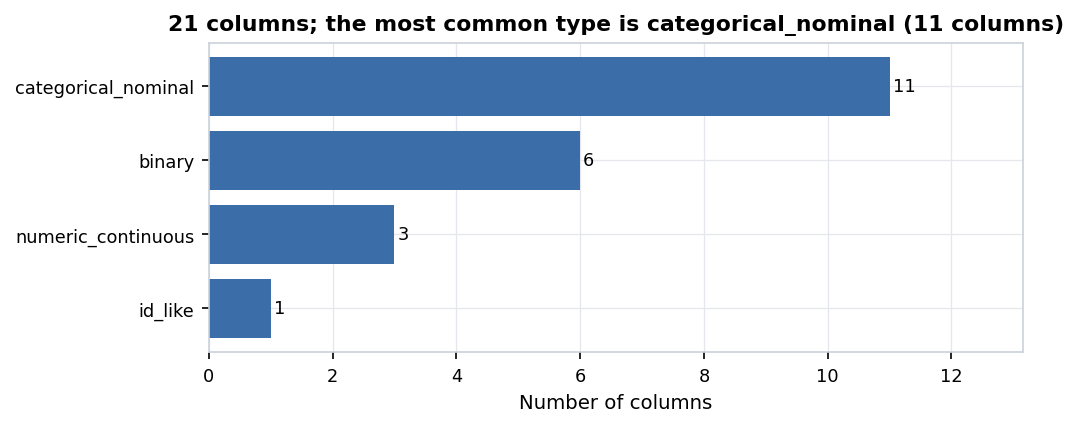

#### 1 of 21 columns have missing values; most is 'TotalCharges' (0.2%)
*Figure 2. 1 of 21 columns have missing values; most is 'TotalCharges' (0.2%).* Percent of rows missing per column (only columns with at least one gap). Red bars are above 40%.


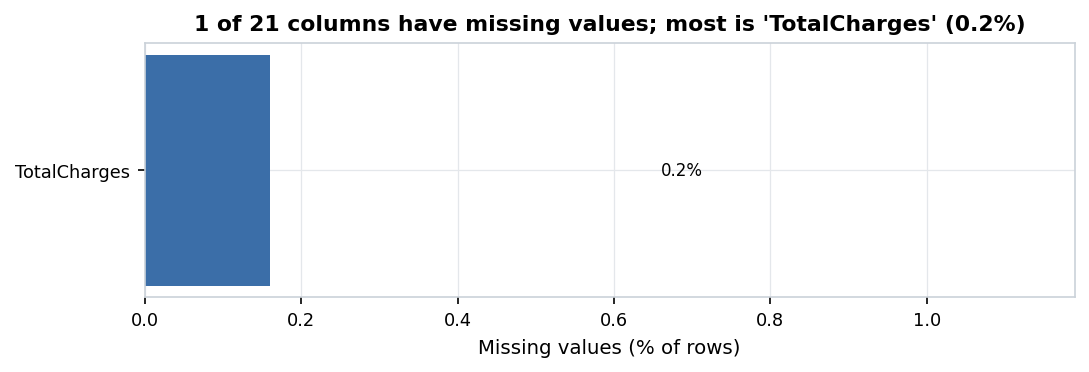

#### Missing values are concentrated: the 10% of rows with the most gaps hold 100.0% of all missing cells
*Figure 3. Missing values are concentrated: the 10% of rows with the most gaps hold 100.0% of all missing cells.* Each red cell is a missing value; rows are sorted by how many gaps they have. A random sample of 500 of 7,043 rows is shown.


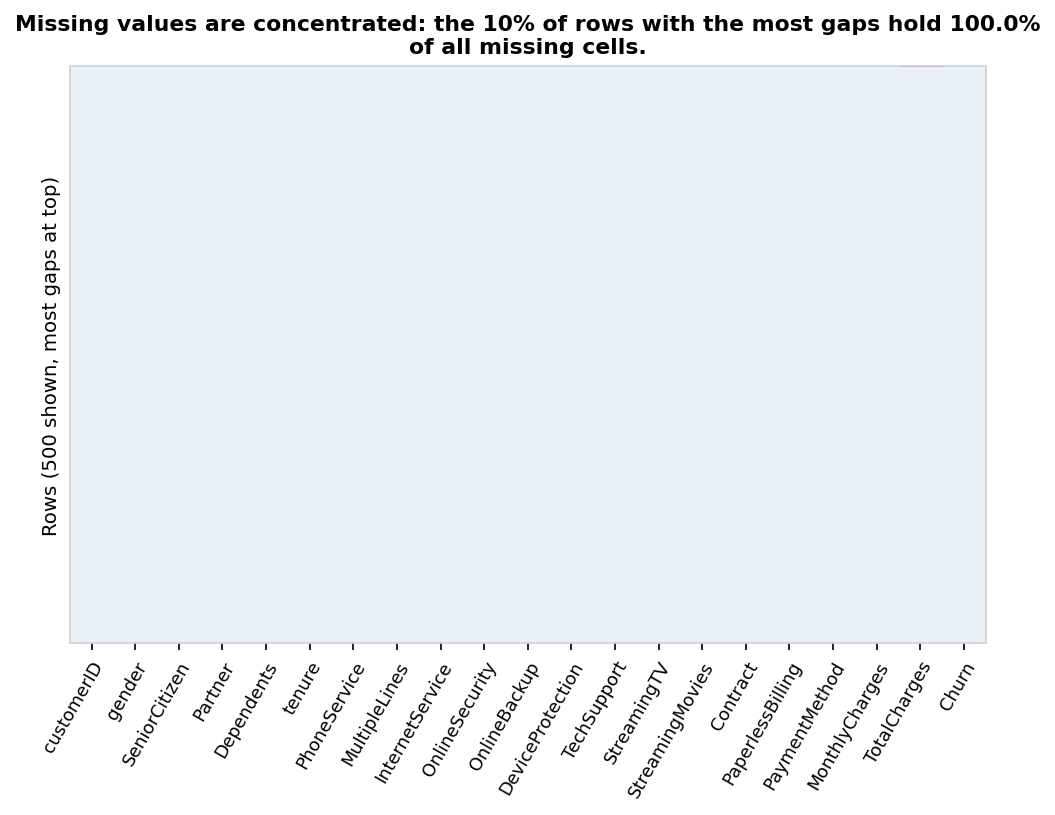

#### Numeric distributions (1/1): most skewed here is 'TotalCharges' (skew +0.96)
*Figure 4. Numeric distributions (1/1): most skewed here is 'TotalCharges' (skew +0.96).* Histogram (with a smooth density curve for many-valued columns) and a box plot per column. Orange line = mean, green dashed line = median; red dots are values beyond 1.5×IQR.


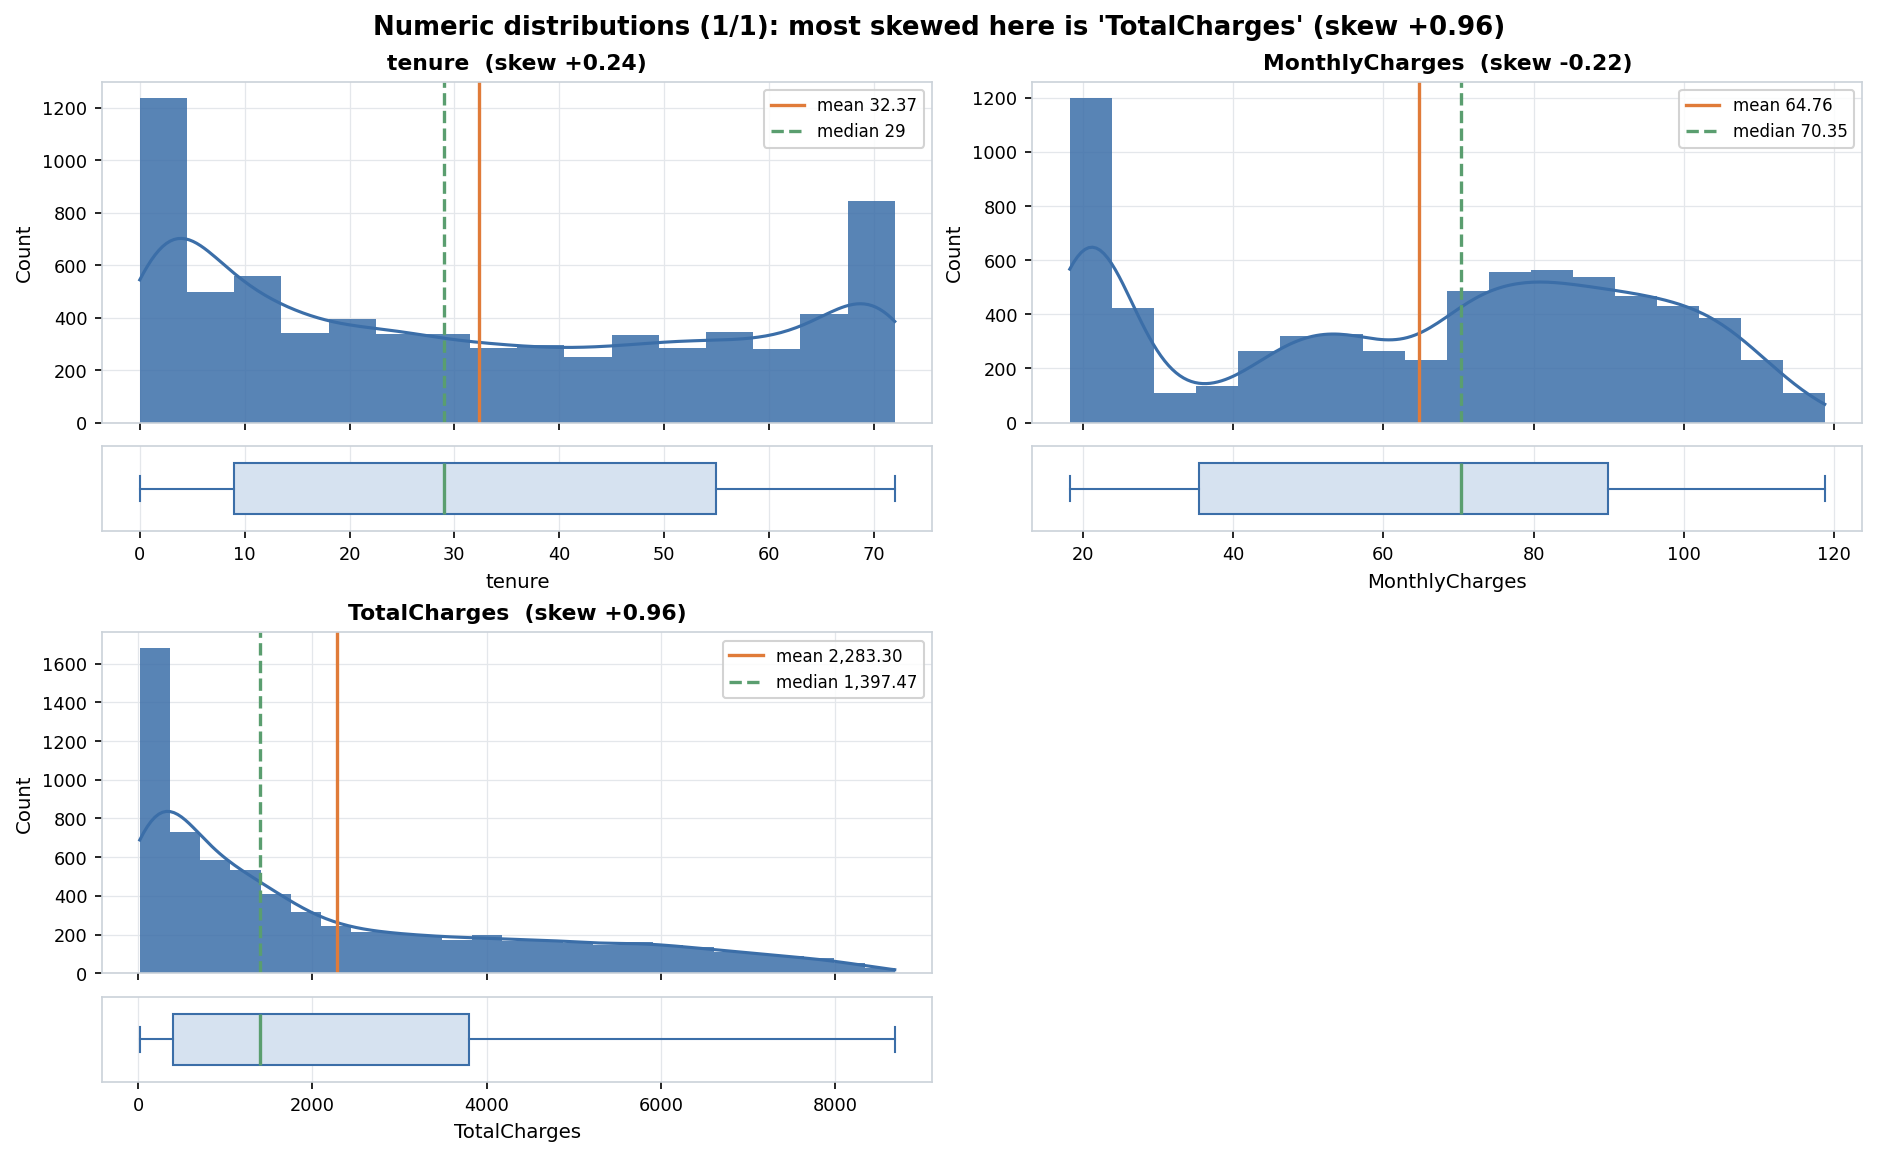

#### Categorical distributions (1/3): most lopsided here is 'PhoneService' (top level 90.3%)
*Figure 5. Categorical distributions (1/3): most lopsided here is 'PhoneService' (top level 90.3%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


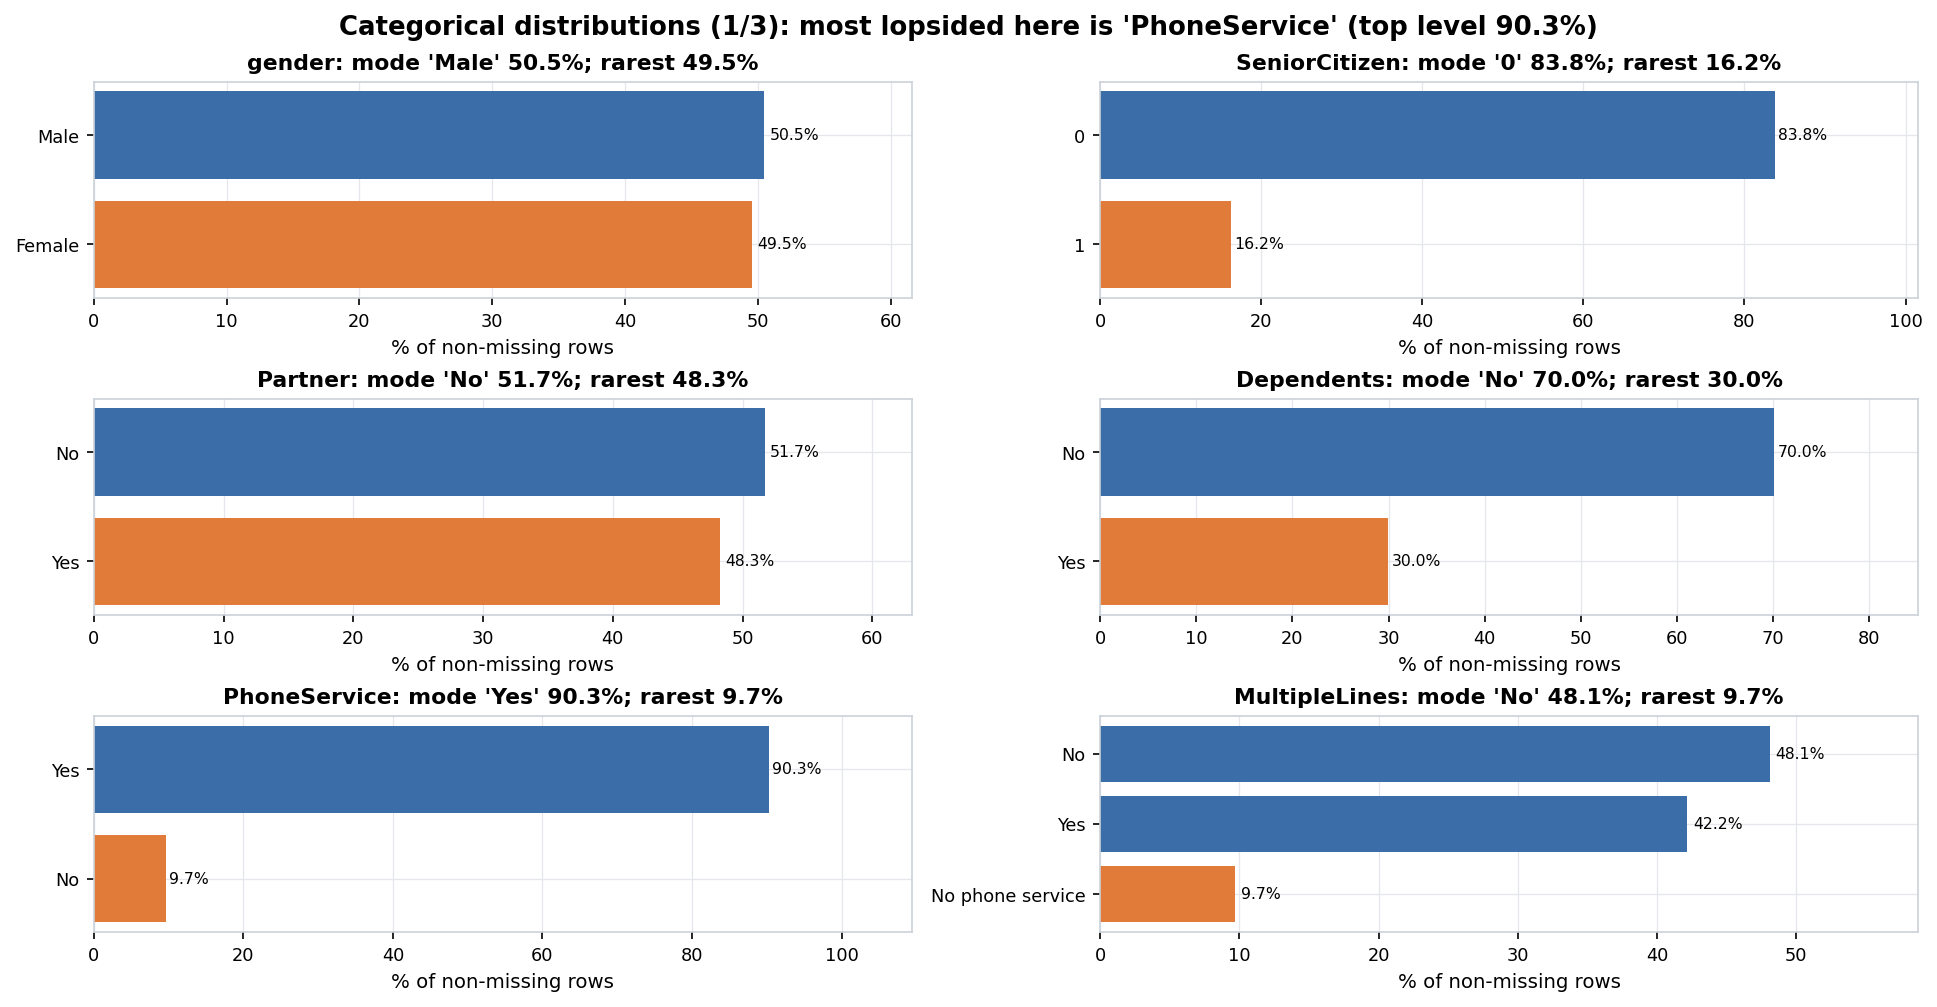

#### Categorical distributions (2/3): most lopsided here is 'OnlineSecurity' (top level 49.7%)
*Figure 6. Categorical distributions (2/3): most lopsided here is 'OnlineSecurity' (top level 49.7%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


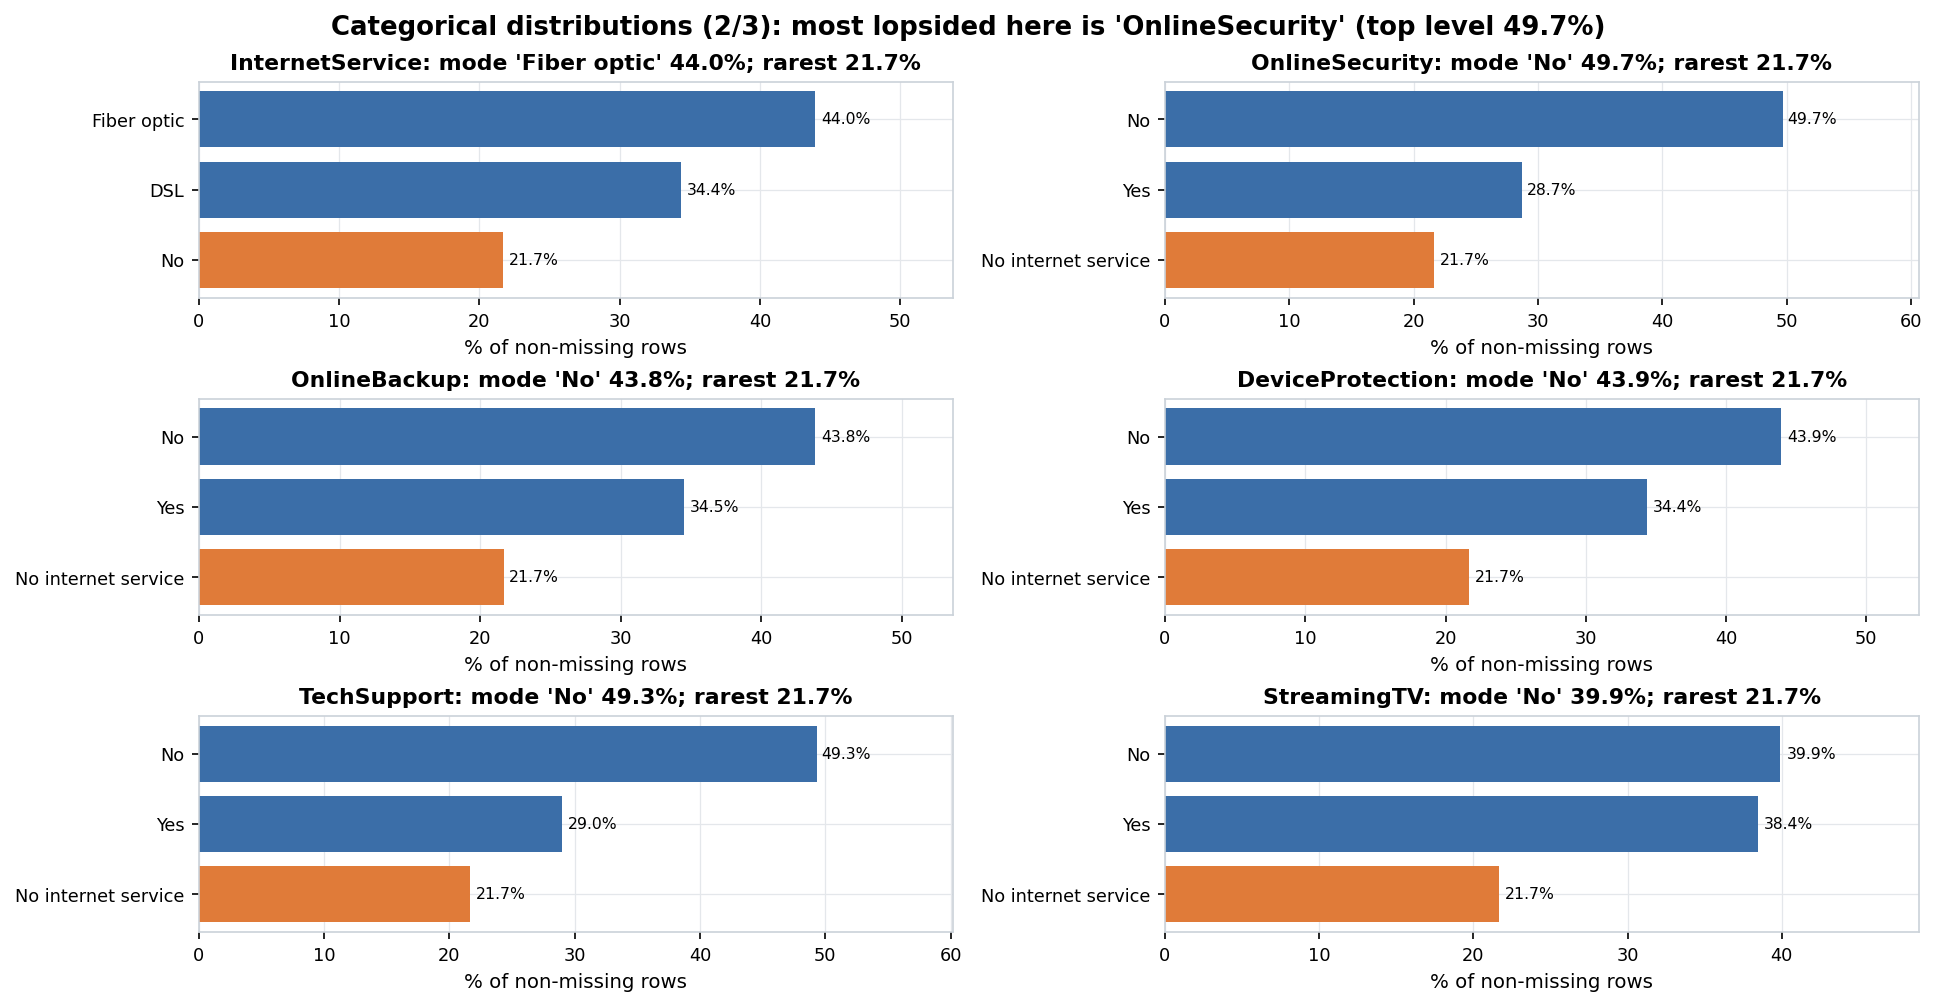

#### Categorical distributions (3/3): most lopsided here is 'Churn' (top level 73.5%)
*Figure 7. Categorical distributions (3/3): most lopsided here is 'Churn' (top level 73.5%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


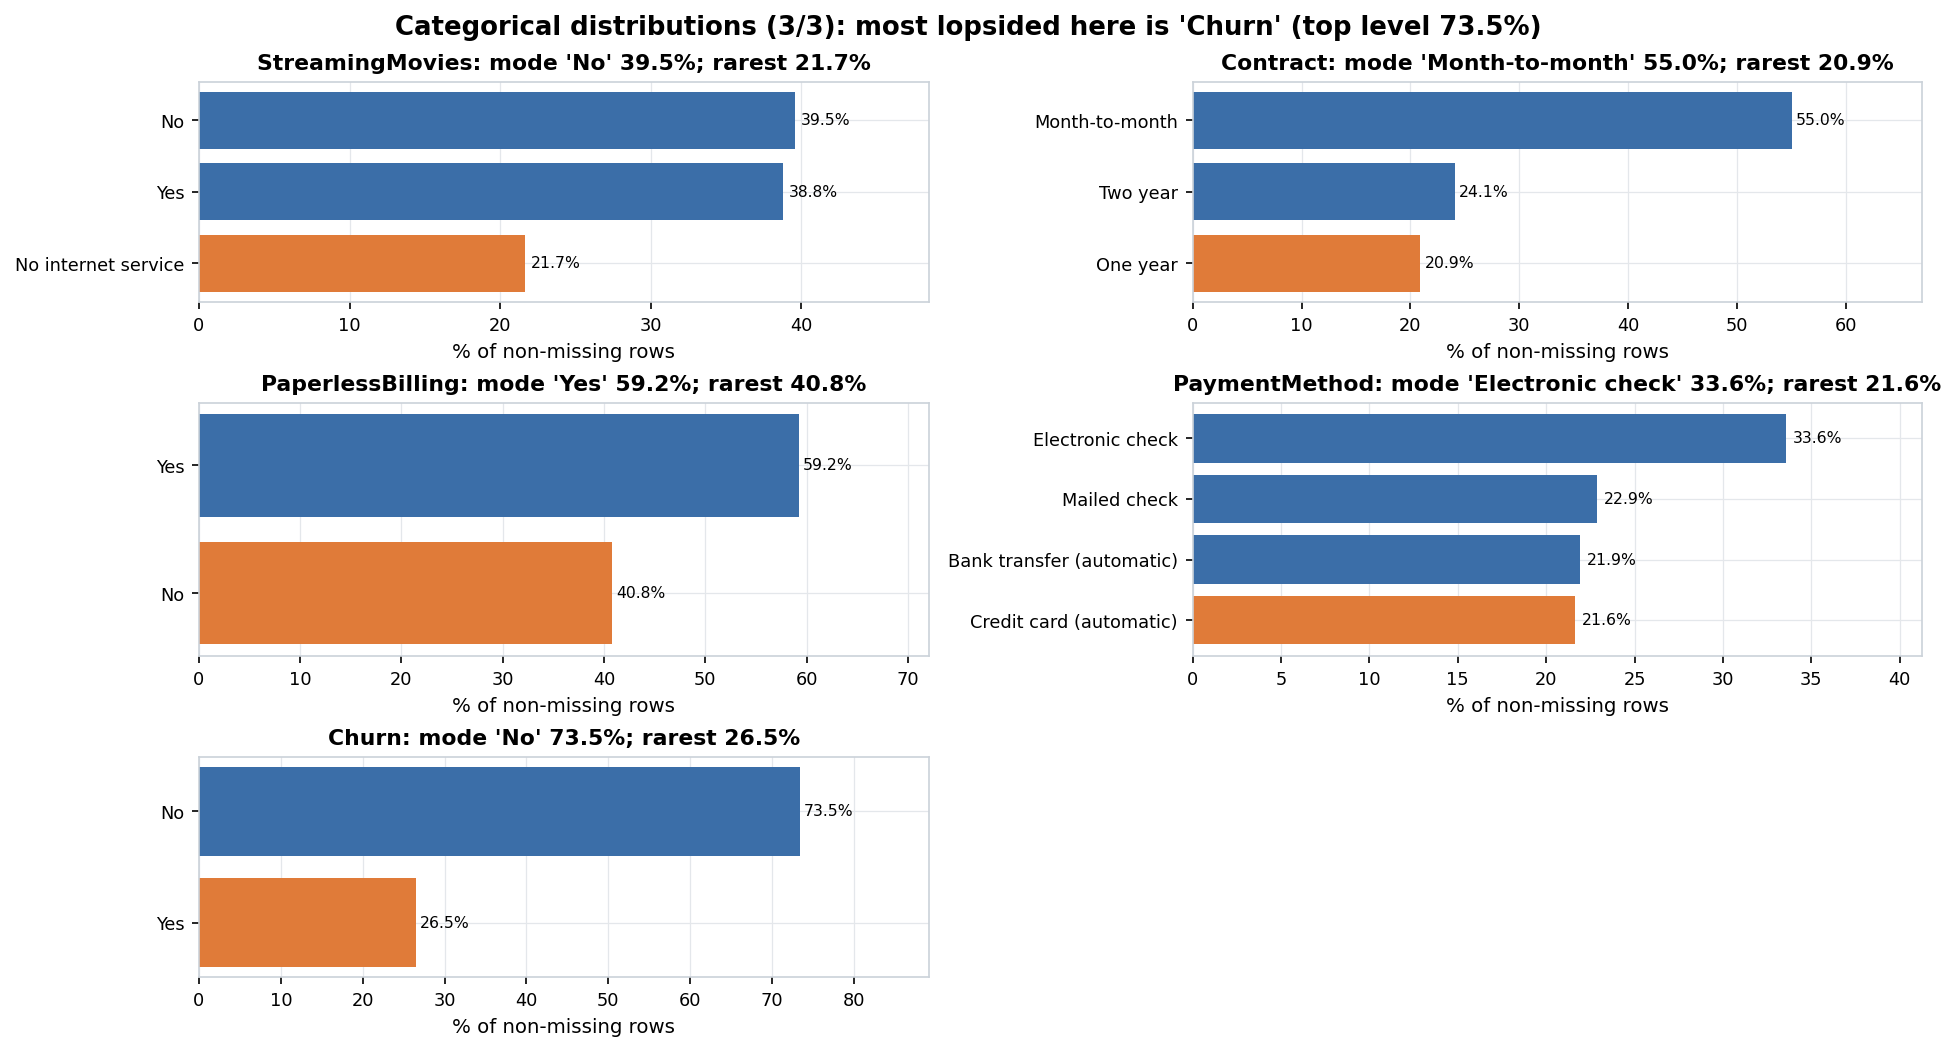

#### 'PaymentMethod' has the most levels (4)
*Figure 8. 'PaymentMethod' has the most levels (4).* Number of distinct values in each categorical or binary column.


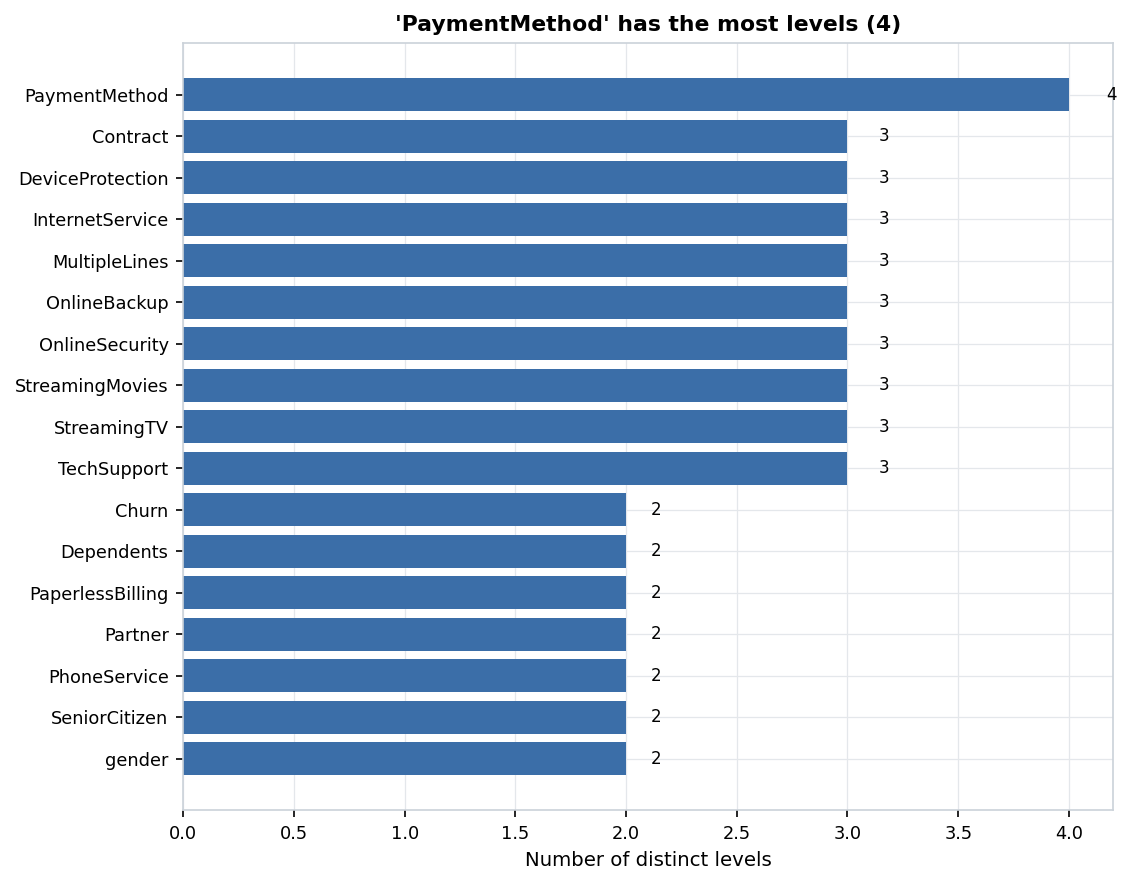

#### Target 'Churn' is mildly imbalanced: smallest class 'Yes' is 26.5% of rows (ratio 2.77:1)
*Figure 9. Target 'Churn' is mildly imbalanced: smallest class 'Yes' is 26.5% of rows (ratio 2.77:1).* Rows per target class. The orange bar is the smallest class. Highly imbalanced = smallest class under 10% of rows; mildly = largest/smallest ratio of 1.5 or more.


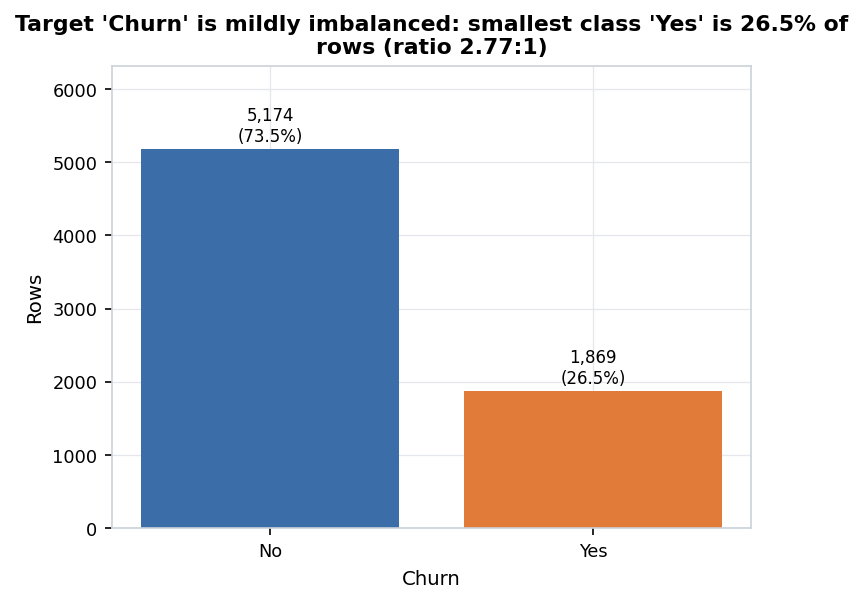

#### The 'Churn' mix changes most across levels of 'Contract' (Cramér's V 0.41)
*Figure 10. The 'Churn' mix changes most across levels of 'Contract' (Cramér's V 0.41).* Share of each target class within each level of the categorical features most associated with the target (bias-corrected Cramér's V). Descriptive coefficients only; no hypothesis tests were run.


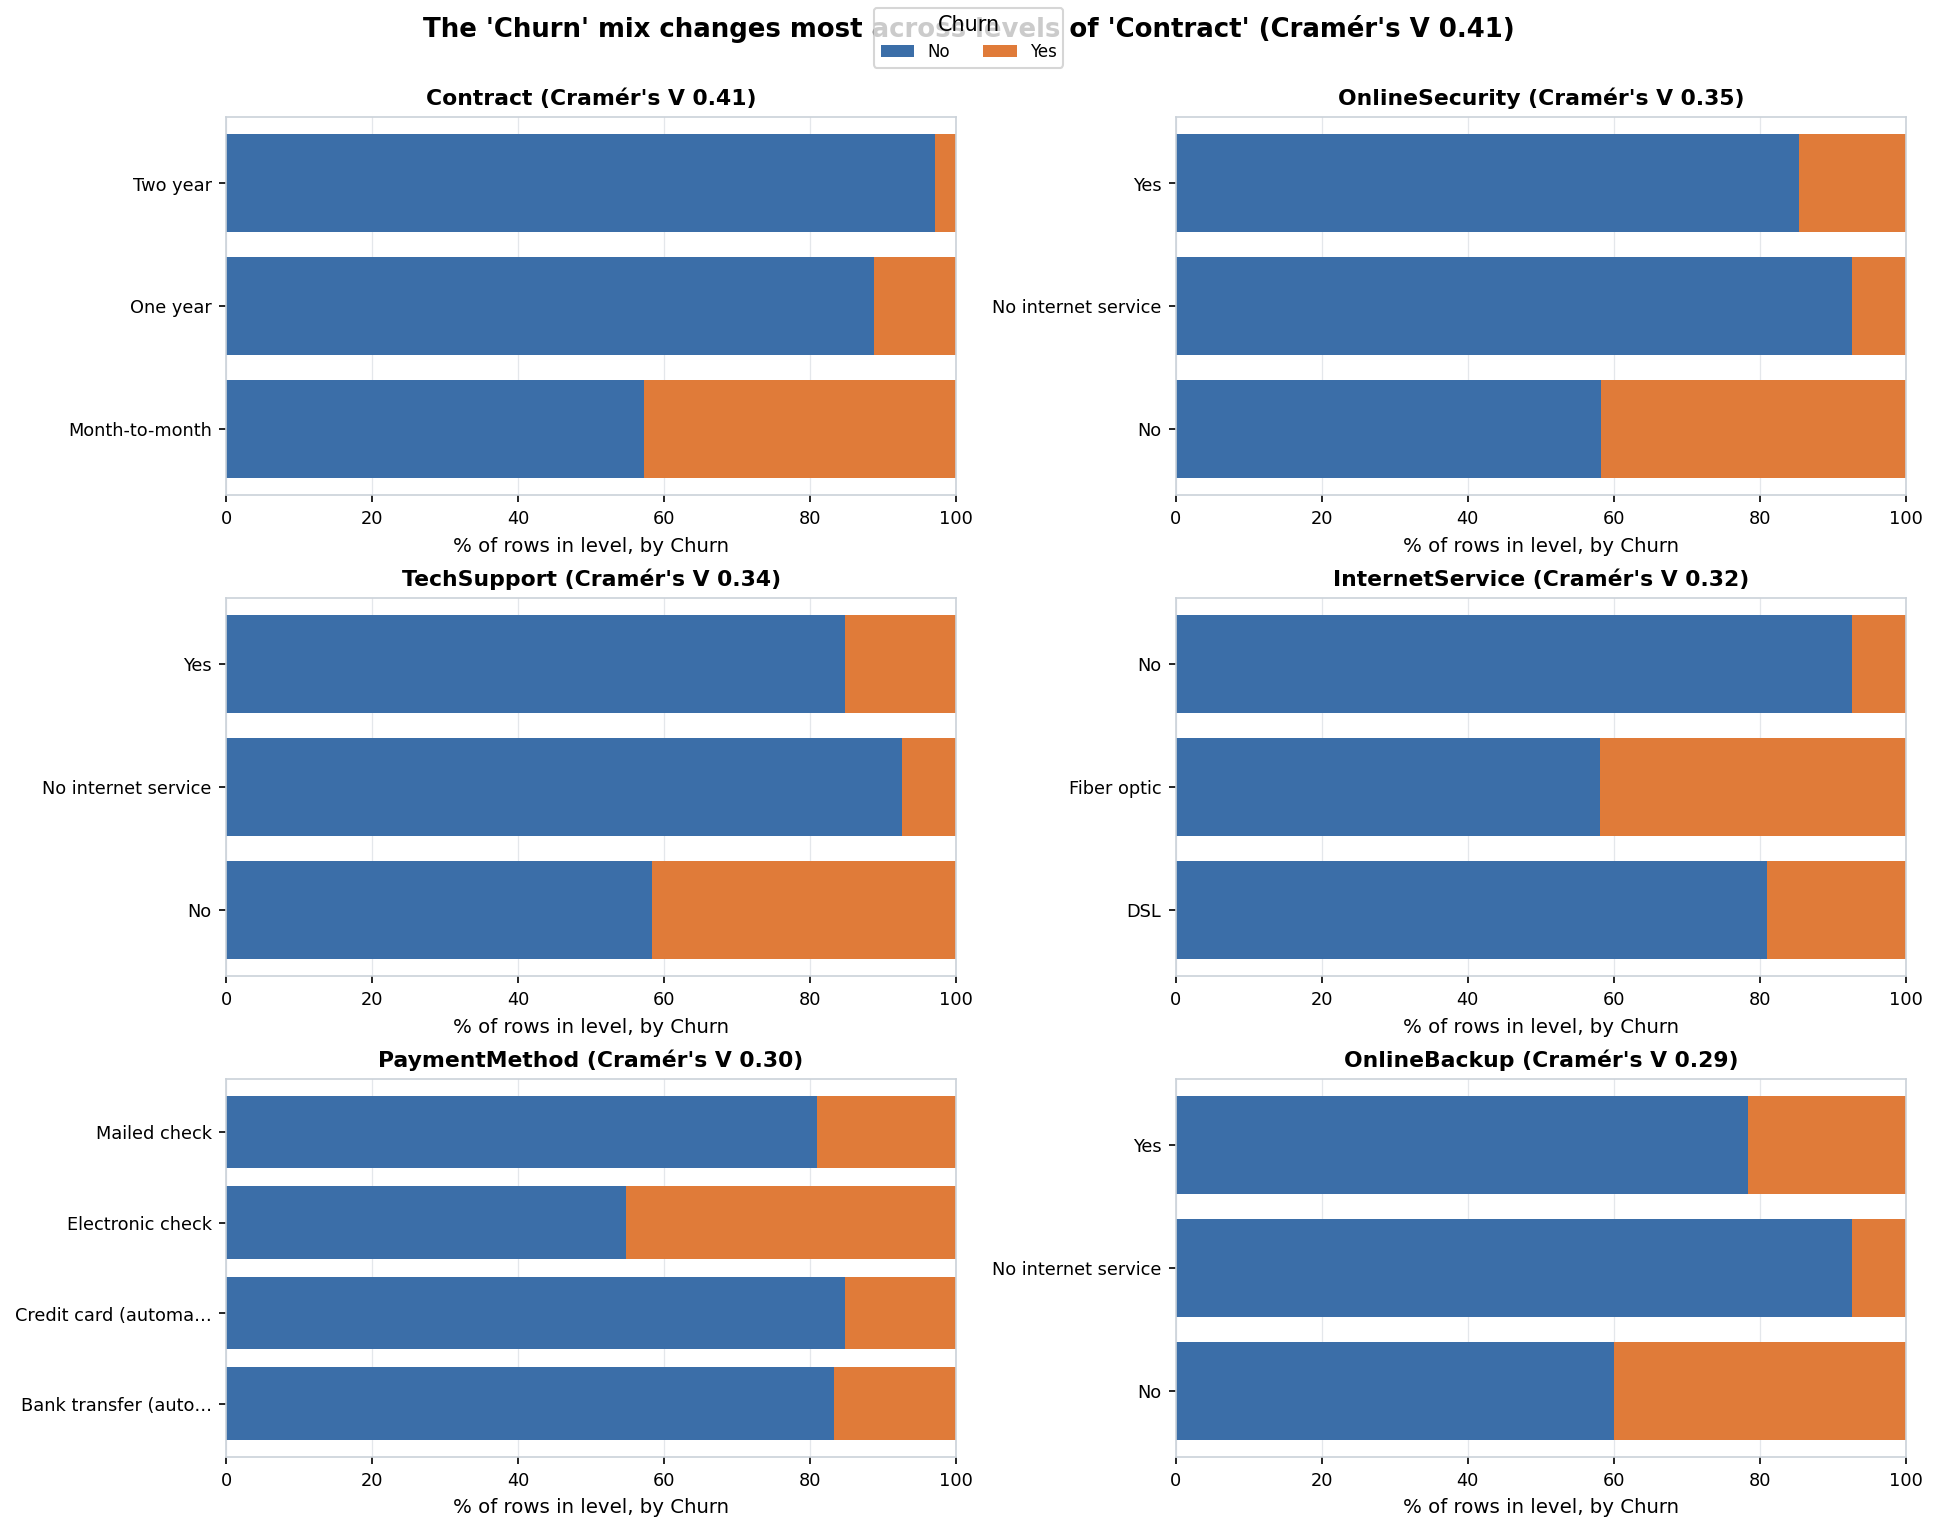

#### Strongest numeric pair: 'tenure' vs 'TotalCharges' (Spearman +0.89, Pearson +0.83)
*Figure 11. Strongest numeric pair: 'tenure' vs 'TotalCharges' (Spearman +0.89, Pearson +0.83).* Correlation between numeric columns (lower triangle). Left: Pearson (linear). Right: Spearman (rank-based). Descriptive coefficients only; no hypothesis tests were run.


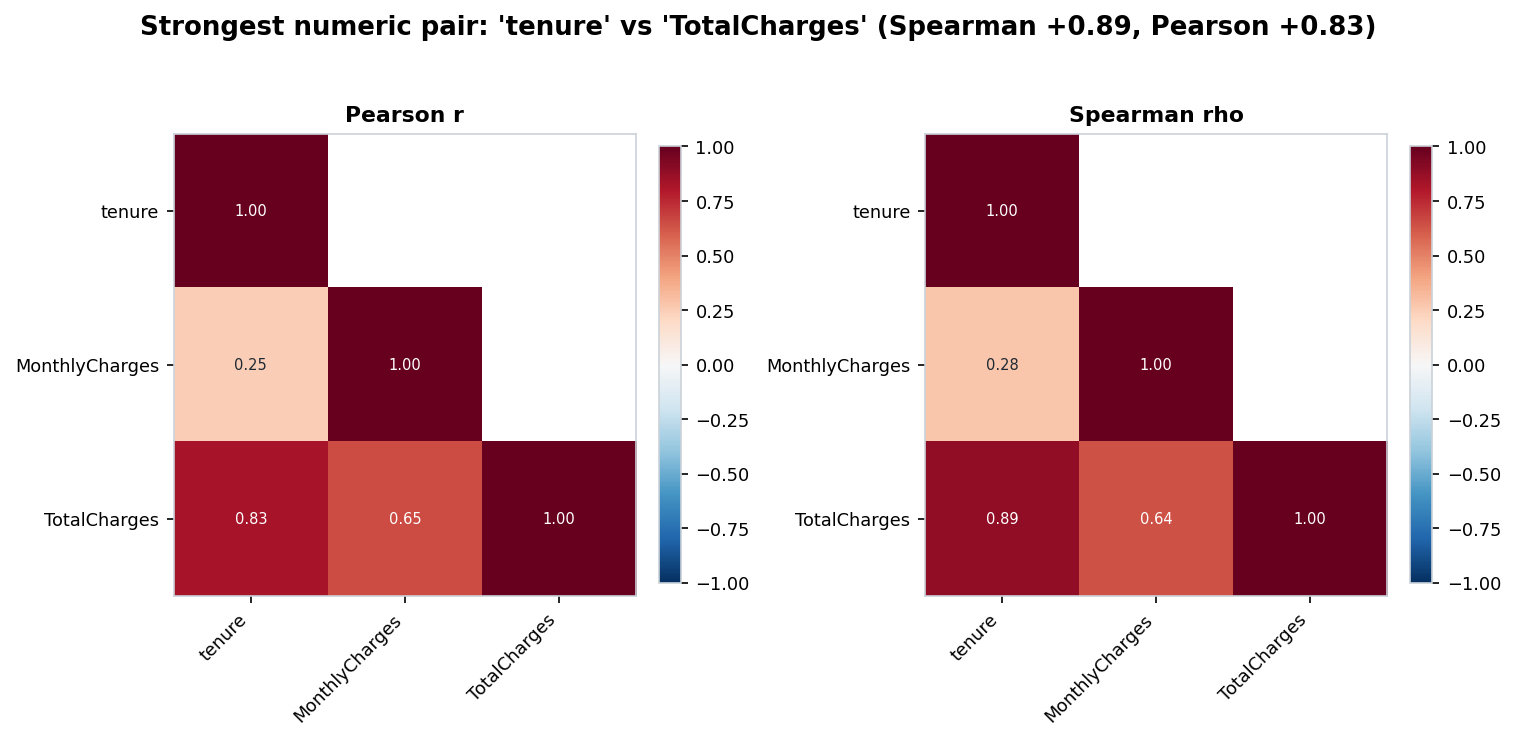

#### Top 3 numeric pairs by |Spearman rho|
*Figure 12. Top 3 numeric pairs by |Spearman rho|.* Scatter plots with a straight-line fit for the most strongly related numeric pairs. Large datasets are randomly sampled for plotting. Descriptive coefficients only; no hypothesis tests were run.


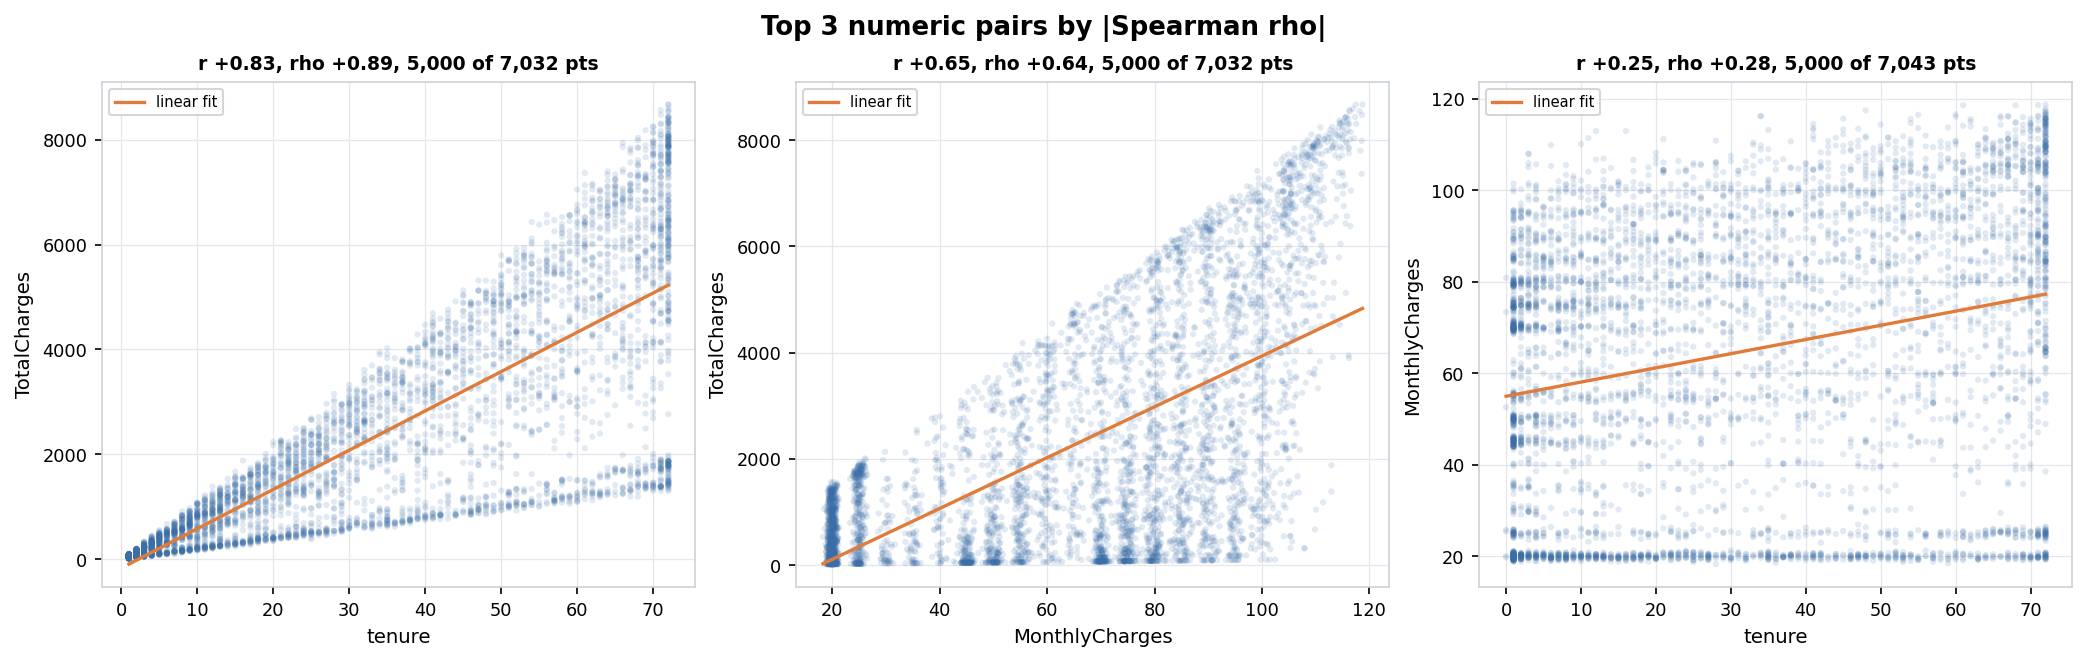

#### 'InternetService' separates 'MonthlyCharges' the most (eta² 0.82 = share of its spread explained by the groups)
*Figure 13. 'InternetService' separates 'MonthlyCharges' the most (eta² 0.82 = share of its spread explained by the groups).* Box plots of numeric columns split by categorical columns with up to 8 levels, for the pairs with the largest eta-squared. Descriptive coefficients only; no hypothesis tests were run.


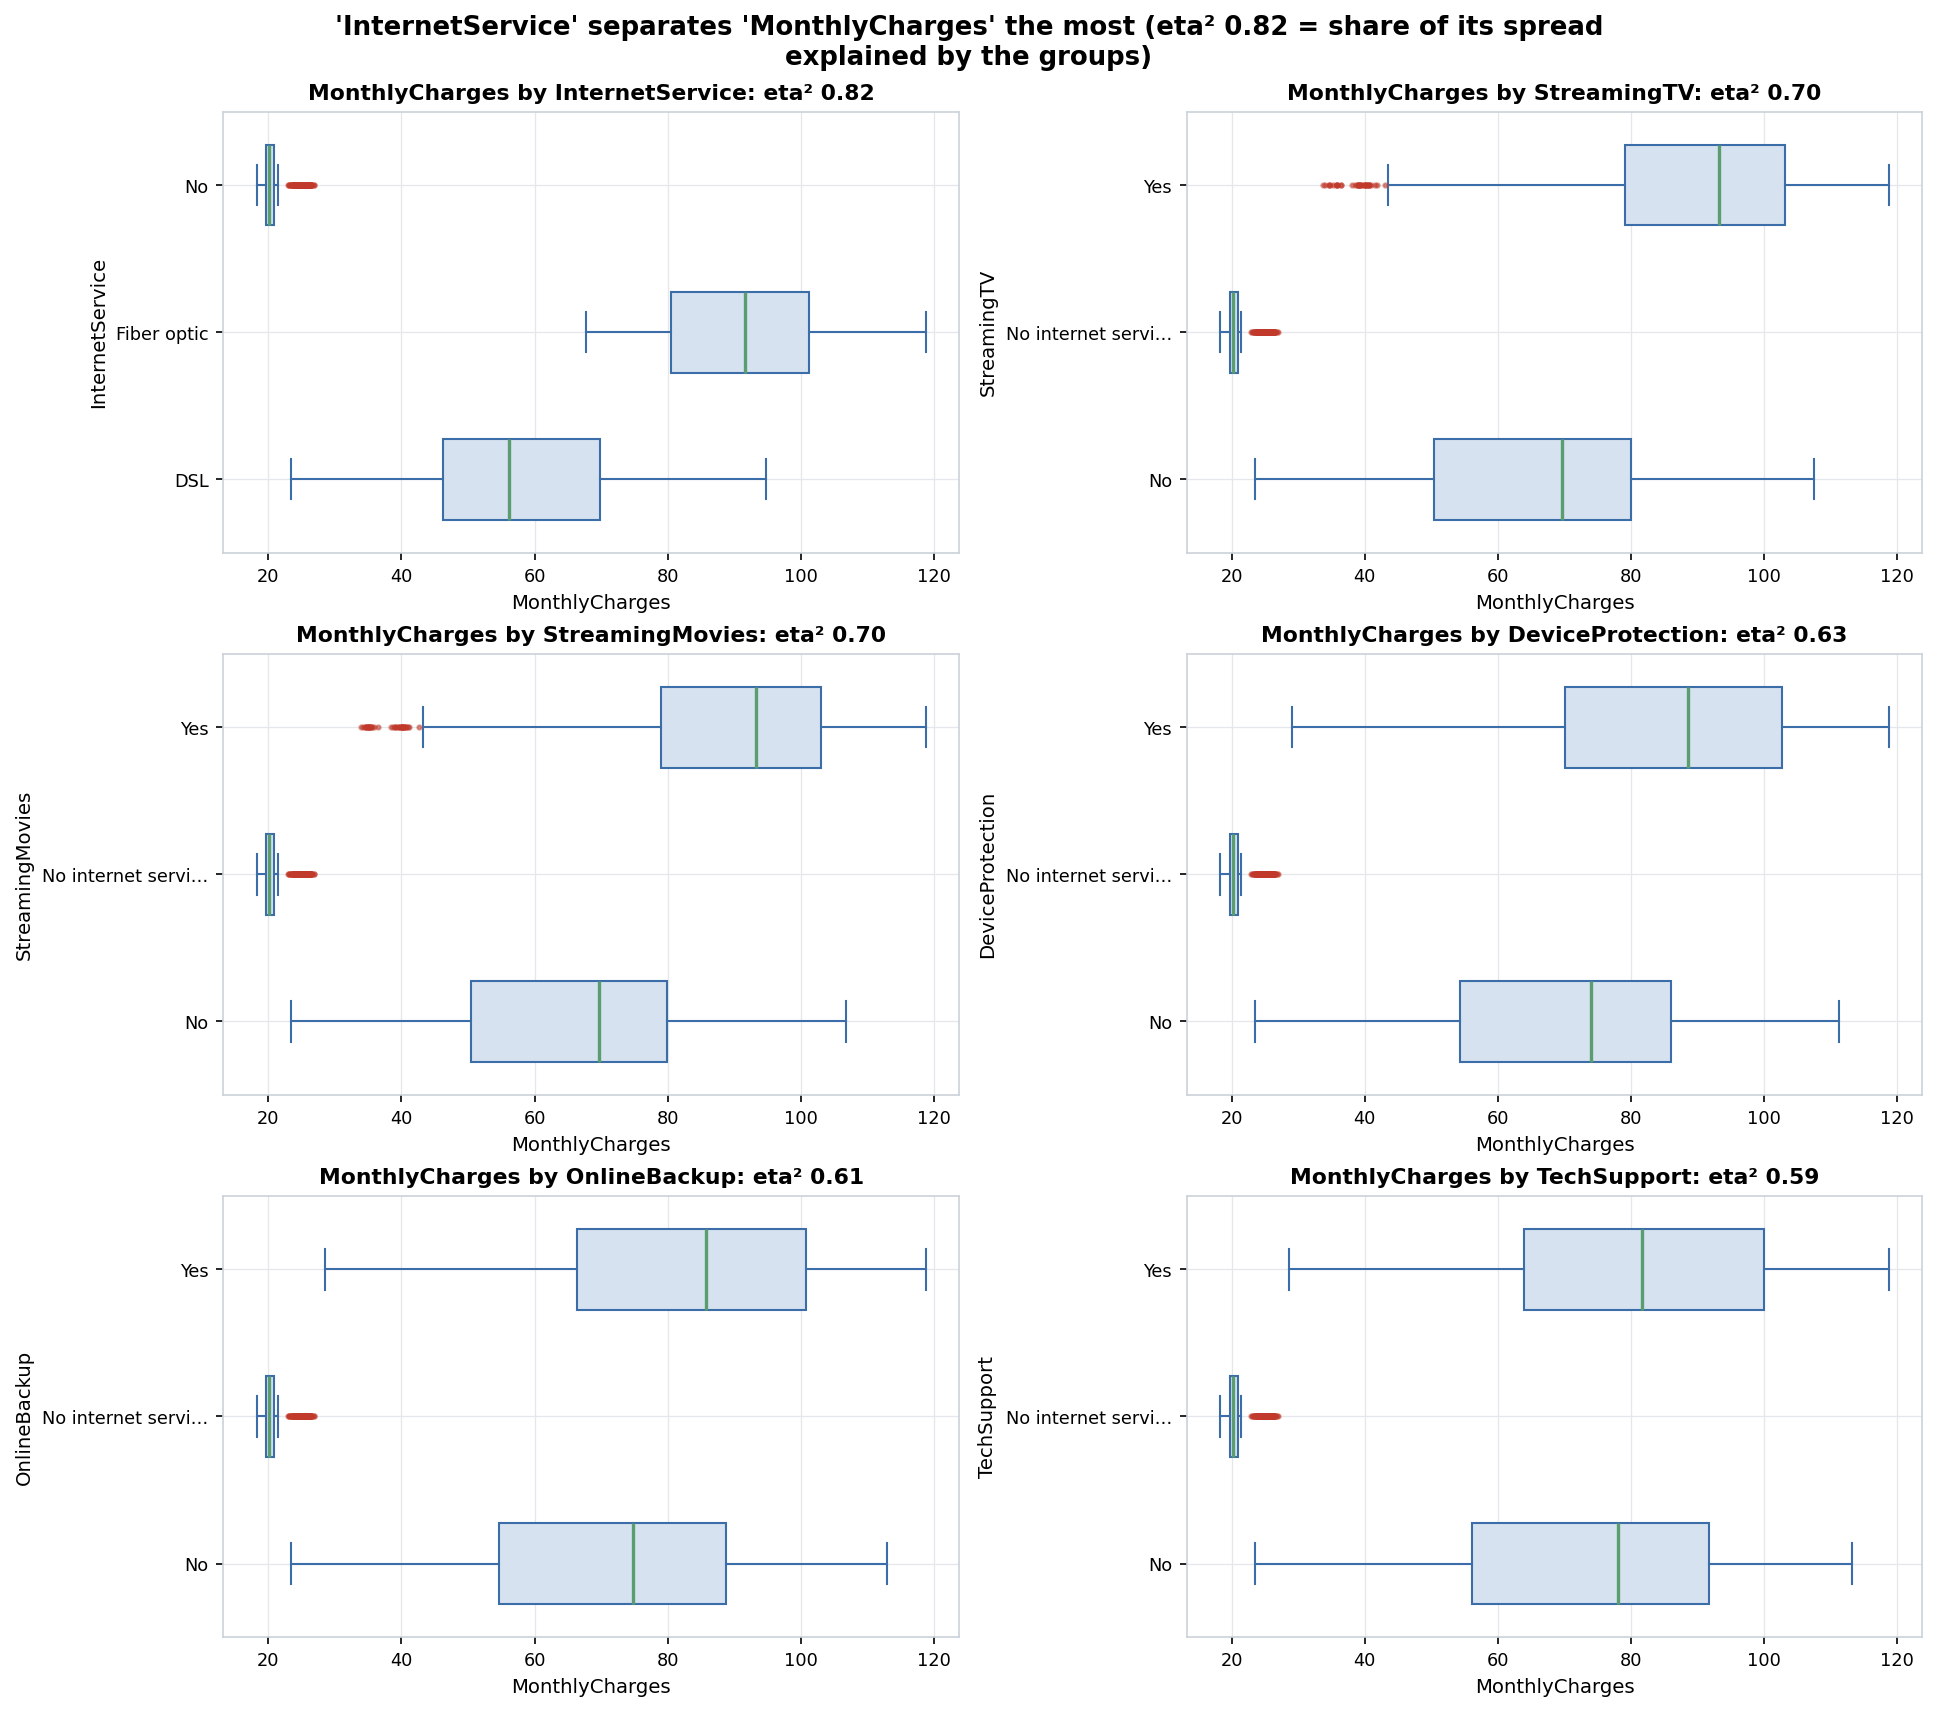

#### Strongest categorical pair: 'PhoneService' vs 'MultipleLines' (Cramér's V 1.00)
*Figure 14. Strongest categorical pair: 'PhoneService' vs 'MultipleLines' (Cramér's V 1.00).* Bias-corrected Cramér's V between categorical/binary columns: 0 = unrelated, 1 = one fully predicts the other. Descriptive coefficients only; no hypothesis tests were run.


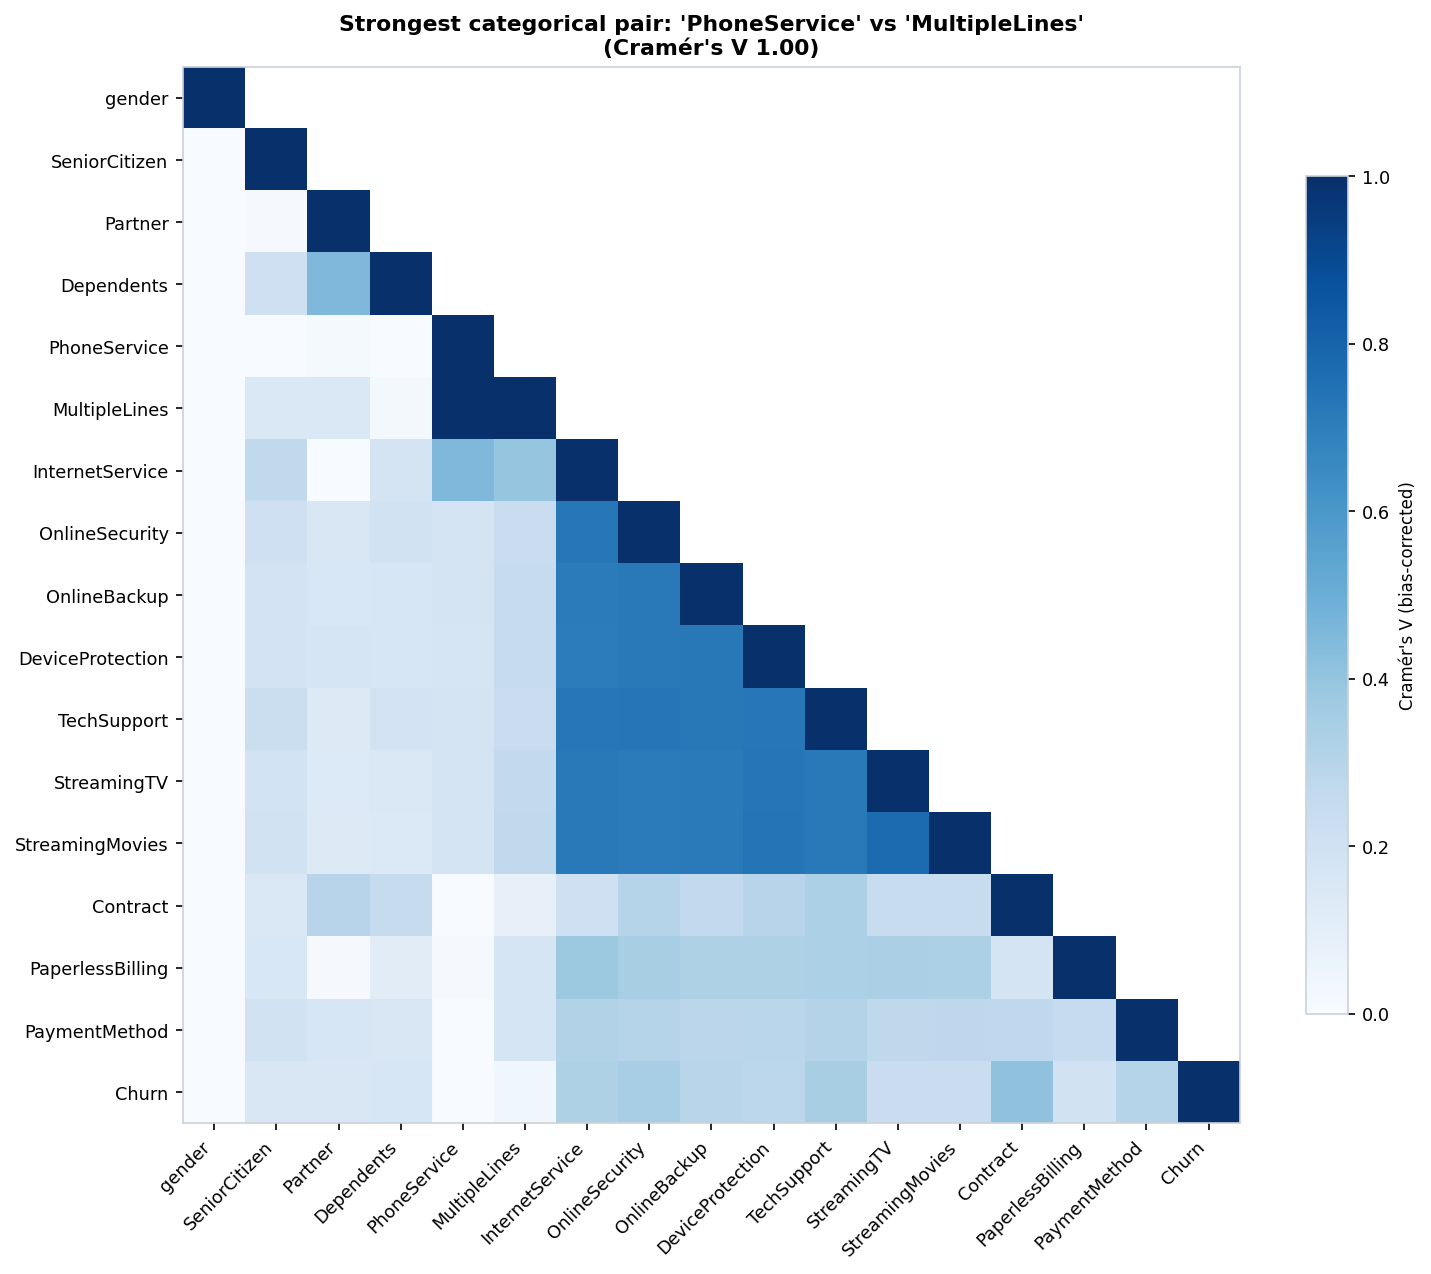

#### Level-by-level mix for the most associated categorical pairs
*Figure 15. Level-by-level mix for the most associated categorical pairs.* For each level of the first column, the share of rows in each level of the second column. Descriptive coefficients only; no hypothesis tests were run.


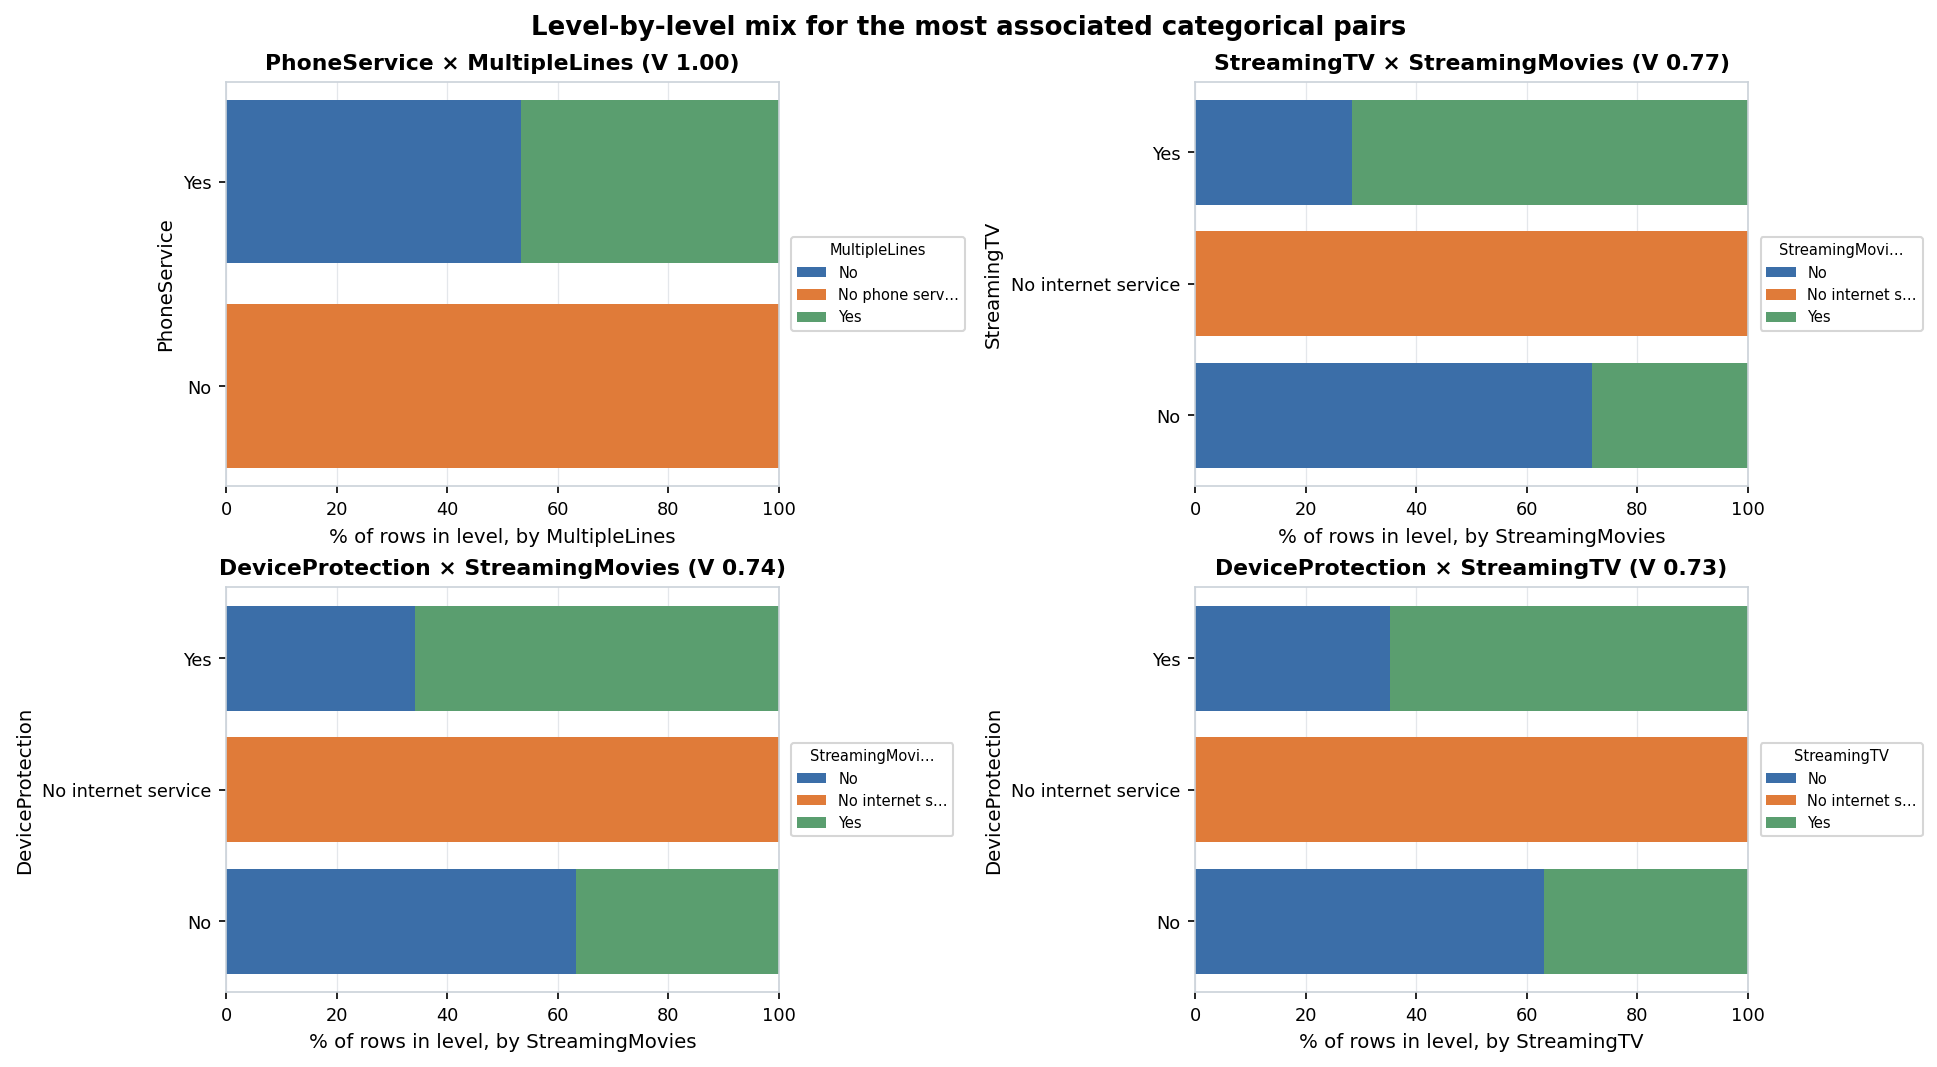

#### 'Contract' has the strongest association with 'Churn' (Cramér's V 0.41)
*Figure 16. 'Contract' has the strongest association with 'Churn' (Cramér's V 0.41).* Every feature ranked by a descriptive association with the target. Different measures are used for different column types, so compare bars of the same colour most directly. Descriptive coefficients only; no hypothesis tests were run.


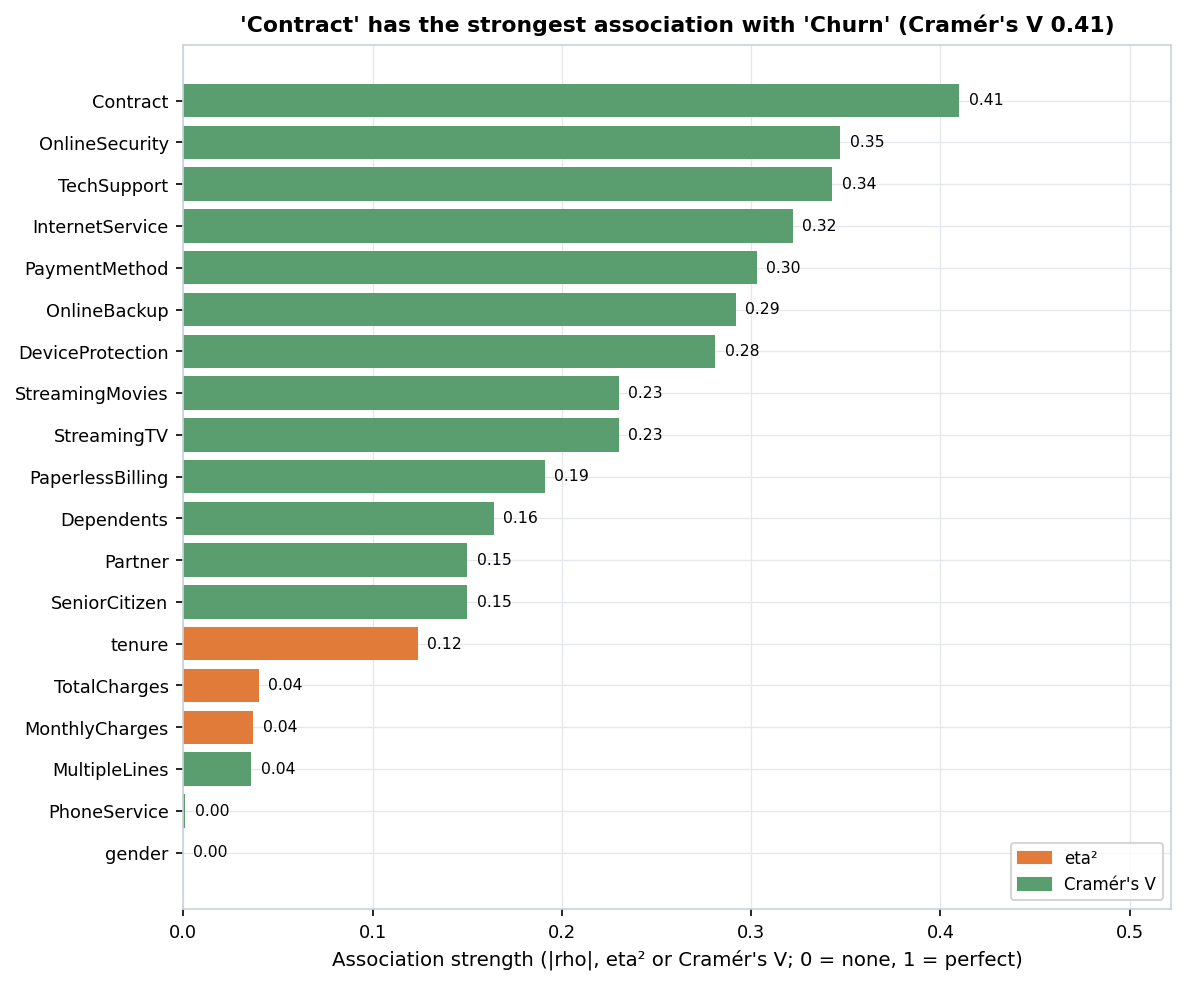

In [4]:
# Display all generated EDA figures and their interpretive captions from outputs/<dataset>/figures/
for png_path in sorted((OUT_DIR / "figures").glob("*.png")):
    display(Markdown(f"### `{png_path.name}`"))
    display(Image(filename=str(png_path)))

## 5. Normalization & Scaling Analysis
**What we did & why:** We evaluated skewness and scale disparity across all numeric columns (`ads.scaling.analyze_scaling`). Right-skewed positive columns (`|skew| > 1.0`, `min >= 0`) are recommended for `log1p` transformation, skewed columns with negative values use `yeo_johnson`, and high scale disparity triggers `zscore` standardization in `<dataset>_scaled.csv` for scale-sensitive models while keeping the primary cleaned dataset unscaled.

In [5]:
display(Markdown((OUT_DIR / "scaling_report.md").read_text(encoding="utf-8")))

# Scaling & Transformation Analysis — `telco_churn`

## Decision Summary

> Primary cleaned output is **not** scaled. The Phase 3 test library is rank-based or scale-invariant (Welch/Mann-Whitney, Spearman, Kruskal, chi-square), so scaling would not change results. Log transforms are recommended for columns [none (no numeric column exceeded skewness threshold)] only for plotting and for parametric/regression use. A scaled copy is provided for TA review and for any future modeling.

## Scale Disparity Across Numeric Features

- **Max standard deviation:** `2266.7714`
- **Min standard deviation:** `24.5595`
- **Scale disparity ratio (`max_std / min_std`):** `92.30x`
- **Z-score standardization recommended for scale-sensitive models (PCA/L1/L2/KNN):** `True`

## Per-Column Transformation Recommendations

| Column | Skewness | Kurtosis | Min | Max | Std | Min >= 0 | Recommended Transform | Reason |
| :--- | ---: | ---: | ---: | ---: | ---: | :---: | :--- | :--- |
| `tenure` | 0.240 | -1.387 | 0 | 72 | 24.559 | True | `none` | Moderate/low skewness (skew=0.24); no non-linear transform needed. |
| `MonthlyCharges` | -0.221 | -1.257 | 18.25 | 118.75 | 30.090 | True | `none` | Moderate/low skewness (skew=-0.22); no non-linear transform needed. |
| `TotalCharges` | 0.962 | -0.232 | 18.8 | 8684.8 | 2266.771 | True | `none` | Moderate/low skewness (skew=0.96); no non-linear transform needed. |

## Generated Convenience Artifacts

- **Scaled CSV (TA review / downstream modeling copy):** `data\cleaned\telco_churn_scaled.csv`


## 6. Key Findings: Automated & Analyst Manual Insights
**What we did & why:** `ads.insights.generate_insights` evaluates deterministic rules across 7 categories (Data Quality, Distributions, Class Balance, Relationships, Cardinality/Structure, Scaling, and Modeling/Testing Implications), backing every number with an `evidence` dictionary in `insights.json`, while preserving our human-written domain analysis in the `MANUAL` block.

In [6]:
display(Markdown((OUT_DIR / "insights.md").read_text(encoding="utf-8")))

# Dataset Insights — `telco_churn`

_The automated insights below are generated by fixed rules from computed values (no LLM). Each number is stored with its evidence in `insights.json`. Relationship numbers are descriptive only; no hypothesis tests were run in Phase 1._

## Automated insights

### Data quality

- **LOW** — Column 'TotalCharges' has 0.16% missing values (n = 11 of 7,043 rows). ([figure](figures/missing_bar.png))
- **INFO** — Column 'customerID' is ID-like and is left out of the analysis (kept in the cleaned file).
- **INFO** — No exact duplicate rows were found.

### Distributions

- **LOW** — 'MonthlyCharges' may have 2 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_distributions_1.png))
- **LOW** — 'tenure' may have 2 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_distributions_1.png))

### Class balance

- **MEDIUM** — Target 'Churn' is mildly imbalanced: the smallest class 'Yes' is 26.54% of rows and the largest 'No' is 73.46% (the largest class is 2.77 times the smallest). ([figure](figures/target_balance.png))

### Relationships (descriptive)

- **MEDIUM** — The categorical feature most associated with target 'Churn' is 'Contract' (Cramér's V = 0.41; descriptive). ([figure](figures/target_relationships.png))
- **LOW** — 'PhoneService' and 'MultipleLines' are associated (bias-corrected Cramér's V = 1; descriptive). ([figure](figures/cramers_v_heatmap.png))
- **LOW** — 'StreamingTV' and 'StreamingMovies' are associated (bias-corrected Cramér's V = 0.77; descriptive). ([figure](figures/cramers_v_heatmap.png))
- **LOW** — Groups of 'InternetService' differ in 'MonthlyCharges': the groups explain 82% of its variance (eta² = 0.82; descriptive). ([figure](figures/numeric_by_category.png))
- **LOW** — Groups of 'StreamingTV' differ in 'MonthlyCharges': the groups explain 70% of its variance (eta² = 0.7; descriptive). ([figure](figures/numeric_by_category.png))
- **LOW** — 'MonthlyCharges' and 'TotalCharges' rise together (Spearman rho = +0.64, Pearson r = +0.65; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — 'tenure' and 'TotalCharges' rise together (Spearman rho = +0.89, Pearson r = +0.83; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — The numeric feature most associated with target 'Churn' is 'tenure' (eta² = 0.12; descriptive). ([figure](figures/target_relationships.png))

### Scaling notes

- **INFO** — Numeric columns differ a lot in spread (largest std is 92.3 times the smallest); z-scores are advised only for scale-sensitive methods such as regularized regression, distance-based methods or PCA.

### Implications for later testing

- **MEDIUM** — Because target 'Churn' is mildly imbalanced, compare groups using rates (% per class) rather than raw counts, and use stratified splits for any later modeling. ([figure](figures/target_balance.png))
- **LOW** — Group sizes are very unbalanced for 'PhoneService': 'Yes' covers 90.32% of rows and 'No' only 682 rows, so comparisons across its levels will rest on few cases. ([figure](figures/categorical_distributions_1.png))

## Manual insights (written by the analyst)

<!-- MANUAL:START -->
- **Structural missingness in `TotalCharges`:** Exactly 11 rows contain whitespace-only strings (`" "`) in `TotalCharges`, causing naive `pd.read_csv()` to misclassify the entire column as `object`. Every single one of those 11 customers has `tenure == 0` (newly signed up customers who have not yet been billed for their first month), meaning the missingness is structurally explained (**MAR** given `tenure == 0`), not random data corruption.
- **Encoded binary demographic (`SeniorCitizen`):** Unlike `Partner` and `Dependents` (`Yes`/`No`), `SeniorCitizen` is encoded as `0`/`1` integers; our dataset config explicitly documents this as categorical/binary so it is treated consistently in group comparisons.
- **Redundant category levels across add-on services:** Six service columns (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) share an identical `"No internet service"` level (21.7% of rows), which is perfectly collinear with `InternetService == "No"`.
- **Contract structure & early-tenure churn hazard:** Customers on `Month-to-month` contracts exhibit the highest churn rate (~42.7%), whereas `One year` (~11.3%) and `Two year` (~2.8%) contracts strongly retain subscribers (Cramér's $V = 0.41$). Churn is heavily concentrated in the first 1-6 months of `tenure` (Spearman $\rho = -0.35$).
- **Collinearity warning (`TotalCharges` vs `tenure x MonthlyCharges`):** `TotalCharges` is approximately the product `tenure * MonthlyCharges` (Pearson $r = +0.83$ with `tenure`), causing opposite-direction univariate associations with `Churn` (`MonthlyCharges` positively associated with churn due to Fiber Optic pricing, while `TotalCharges` is negatively associated with churn because high `TotalCharges` requires long `tenure`).
- **Target findings for Phase 5 benchmark recovery:** (1) `Contract <-> Churn` (strong categorical association), (2) `tenure <-> Churn` (strong negative relationship), (3) `InternetService (Fiber optic) <-> Churn` (higher churn), (4) `OnlineSecurity / TechSupport <-> Churn` (protective effect), and (5) `PaymentMethod (Electronic check) <-> Churn`.
<!-- MANUAL:END -->
